# Practical Assignment 04 - Variant 9: SOM Lattice Size and Mapping Quality
Kohonen SOMs (3x3, 5x5, 8x8, 10x10, 5 seeds each) on DenseNet121 embeddings of ODIR-5K fundus images.
All computation is in `scripts/04_som_experiments.py`; this notebook runs it (optional) and shows the saved results.

In [1]:
import json, runpy
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs" / "assignment04"
RERUN = False  # True: retrain all 20 SOMs (about 2 minutes on CPU)
if RERUN or not (OUT / "results.json").exists():
    runpy.run_path(str(ROOT / "scripts" / "04_som_experiments.py"), run_name="__main__")
res = json.load(open(OUT / "results.json", encoding="utf-8"))
print(res["data"]); print(res["settings"])

{'features': '1024-d DenseNet121 embeddings (verified), StandardScaler + PCA fitted on train only', 'pca_components': 32, 'pca_explained_variance': 0.7331632823875716, 'n_train': 4468, 'n_val': 964, 'n_test': 957, 'abnormal_fraction_train': 0.5499104744852283}
{'sizes': ['3x3', '5x5', '8x8', '10x10'], 'seeds': [42, 43, 44, 45, 46], 'epochs': 20, 'presentations_per_map': 89360, 'lattice': 'rectangular', 'neighbourhood': 'Gaussian', 'init': 'random training samples', 'learning_rate': '0.5 -> 0.01 exponential', 'sigma': 'max(rows, cols)/2 -> 0.5 exponential', 'topographic_error': 'BMU and 2nd BMU not 4-neighbours', 'label_agreement': 'unit majority label from train hits, applied to test (interpretation only)'}


## 1. Comparison of lattice sizes (mean ± std over 5 seeds)

,Lattice,QE train,QE test,TE train,TE test,Empty units % (train),Train time s,Label agreement (test)
0,3x3,21.484 ± 0.025,21.400 ± 0.045,0.131 ± 0.012,0.130 ± 0.013,0.0 ± 0.0,1.3 ± 0.1,0.562 ± 0.006
1,5x5,19.886 ± 0.026,19.932 ± 0.054,0.232 ± 0.010,0.233 ± 0.023,0.0 ± 0.0,1.5 ± 0.1,0.581 ± 0.008
2,8x8,18.635 ± 0.014,18.852 ± 0.020,0.219 ± 0.009,0.262 ± 0.008,0.0 ± 0.0,2.3 ± 0.1,0.584 ± 0.016
3,10x10,17.988 ± 0.016,18.323 ± 0.055,0.216 ± 0.004,0.258 ± 0.014,0.0 ± 0.0,2.8 ± 0.1,0.589 ± 0.015


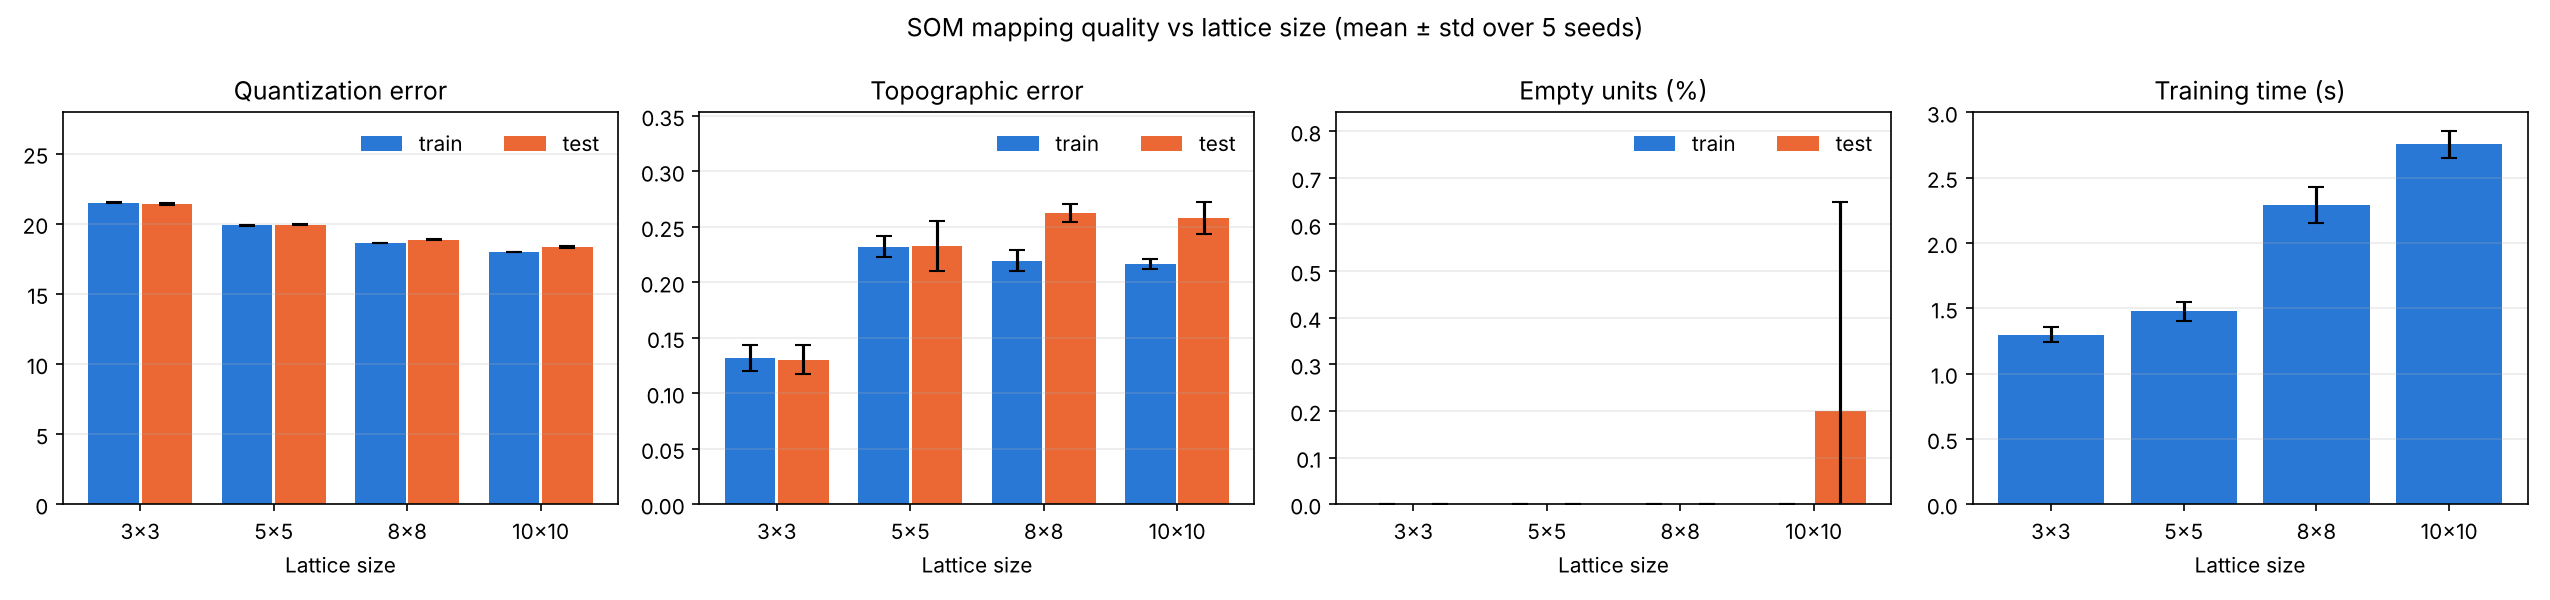

In [2]:
display(pd.read_csv(OUT / "metrics" / "som_comparison_table.csv"))
display(Image(filename=str(OUT / "figures" / "som_metrics_comparison.png")))

## 2. U-matrix, hit maps, Normal vs Abnormal, component planes

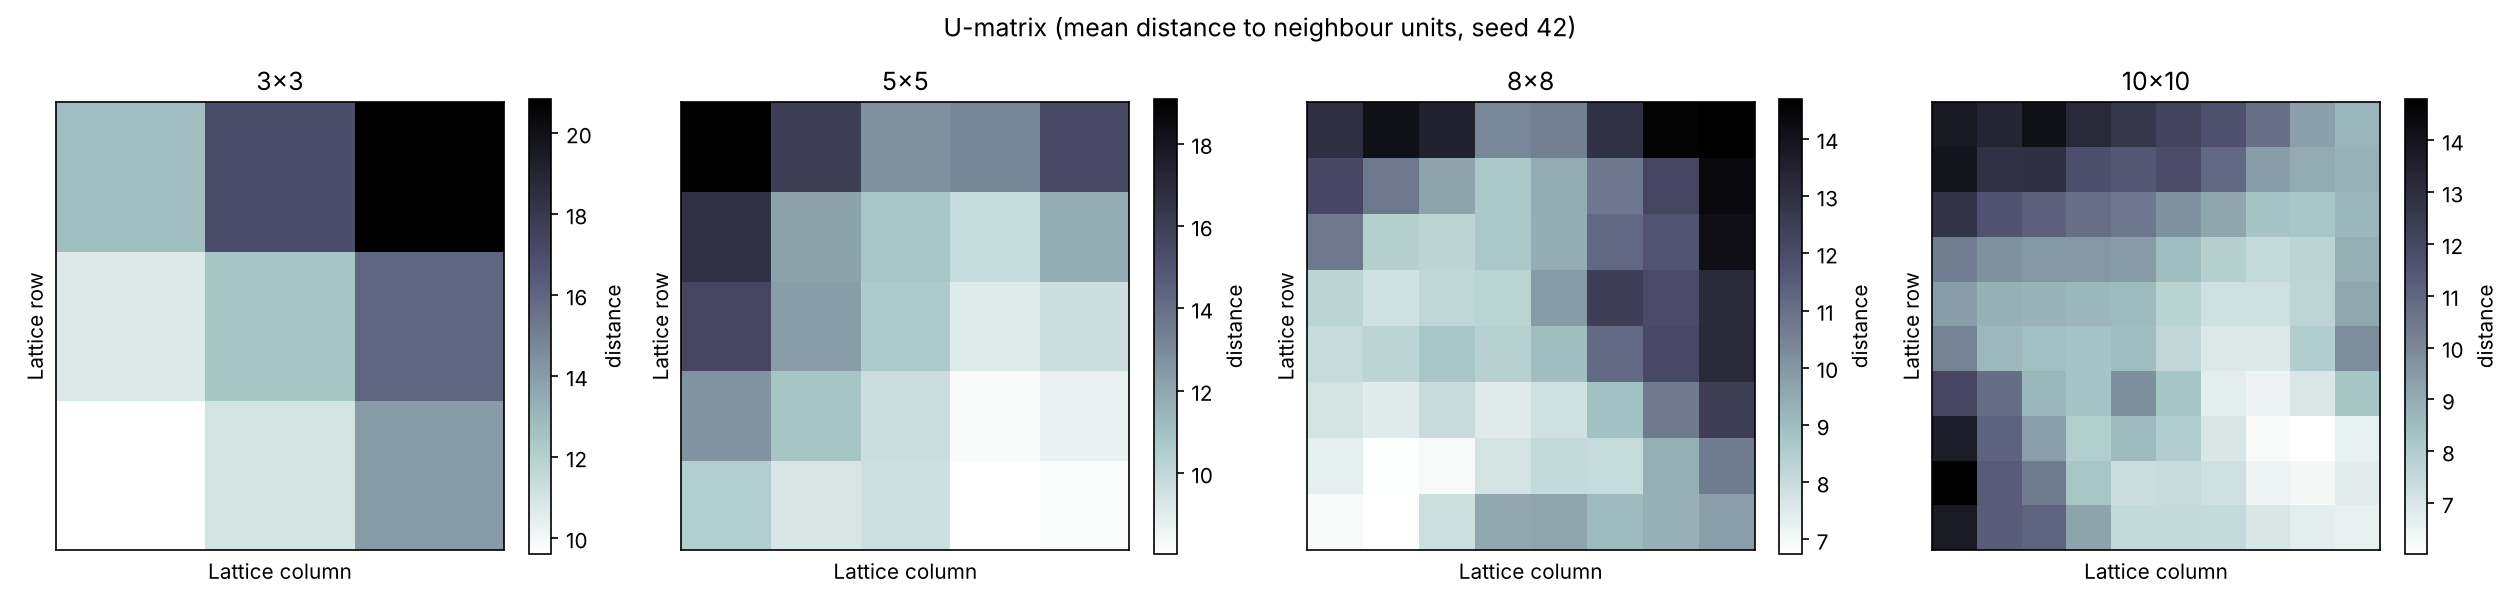

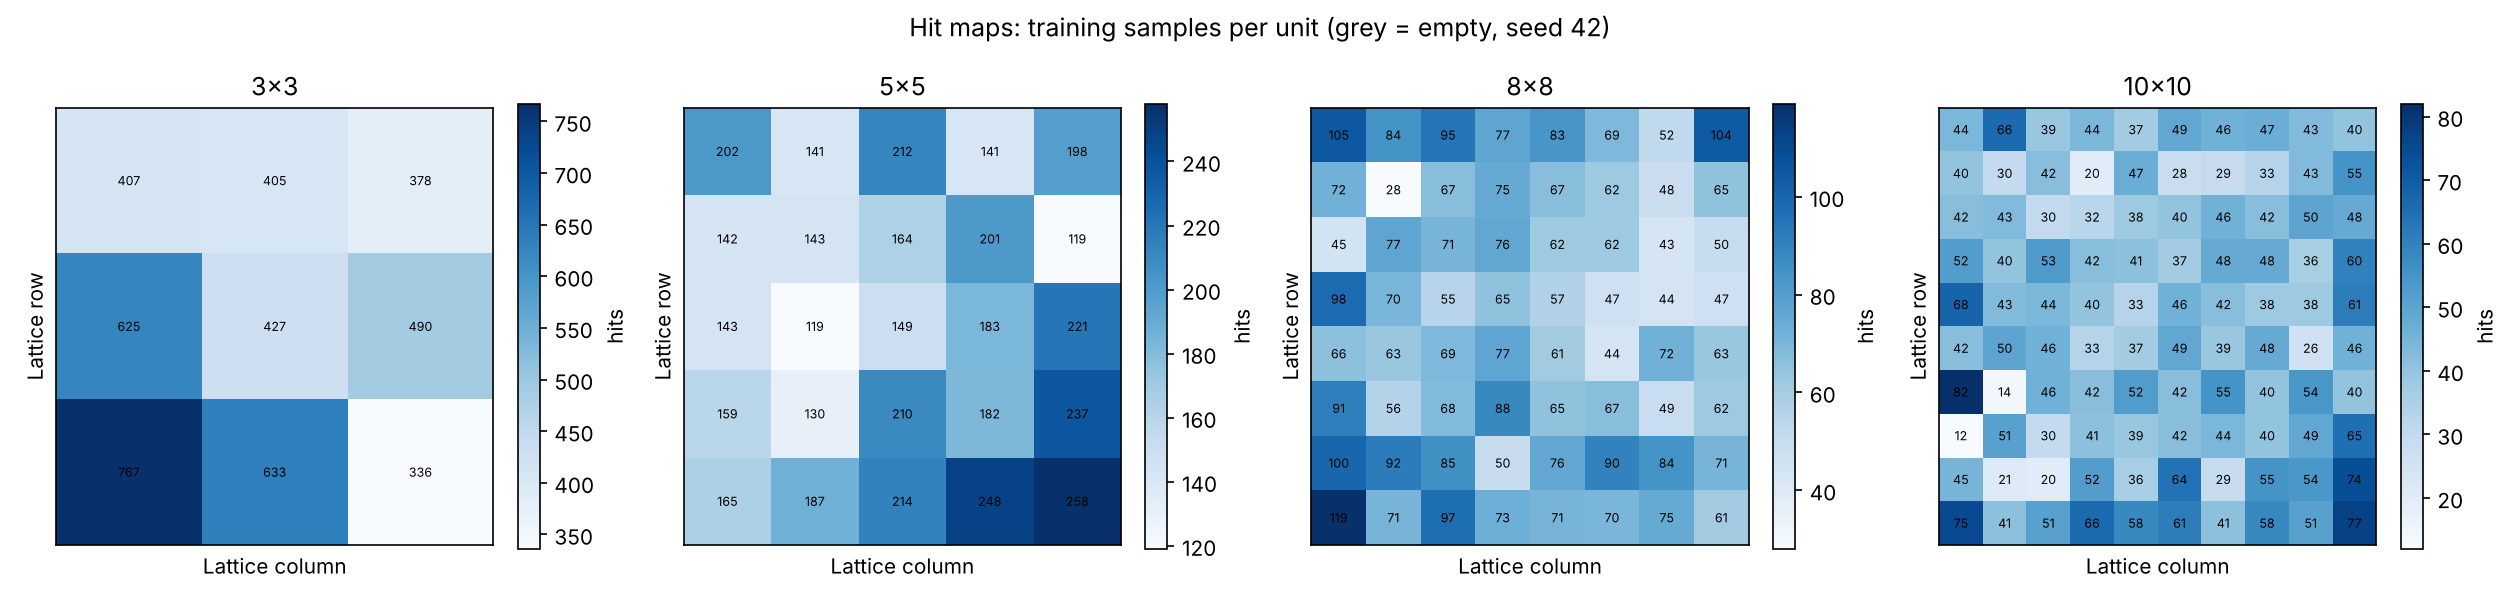

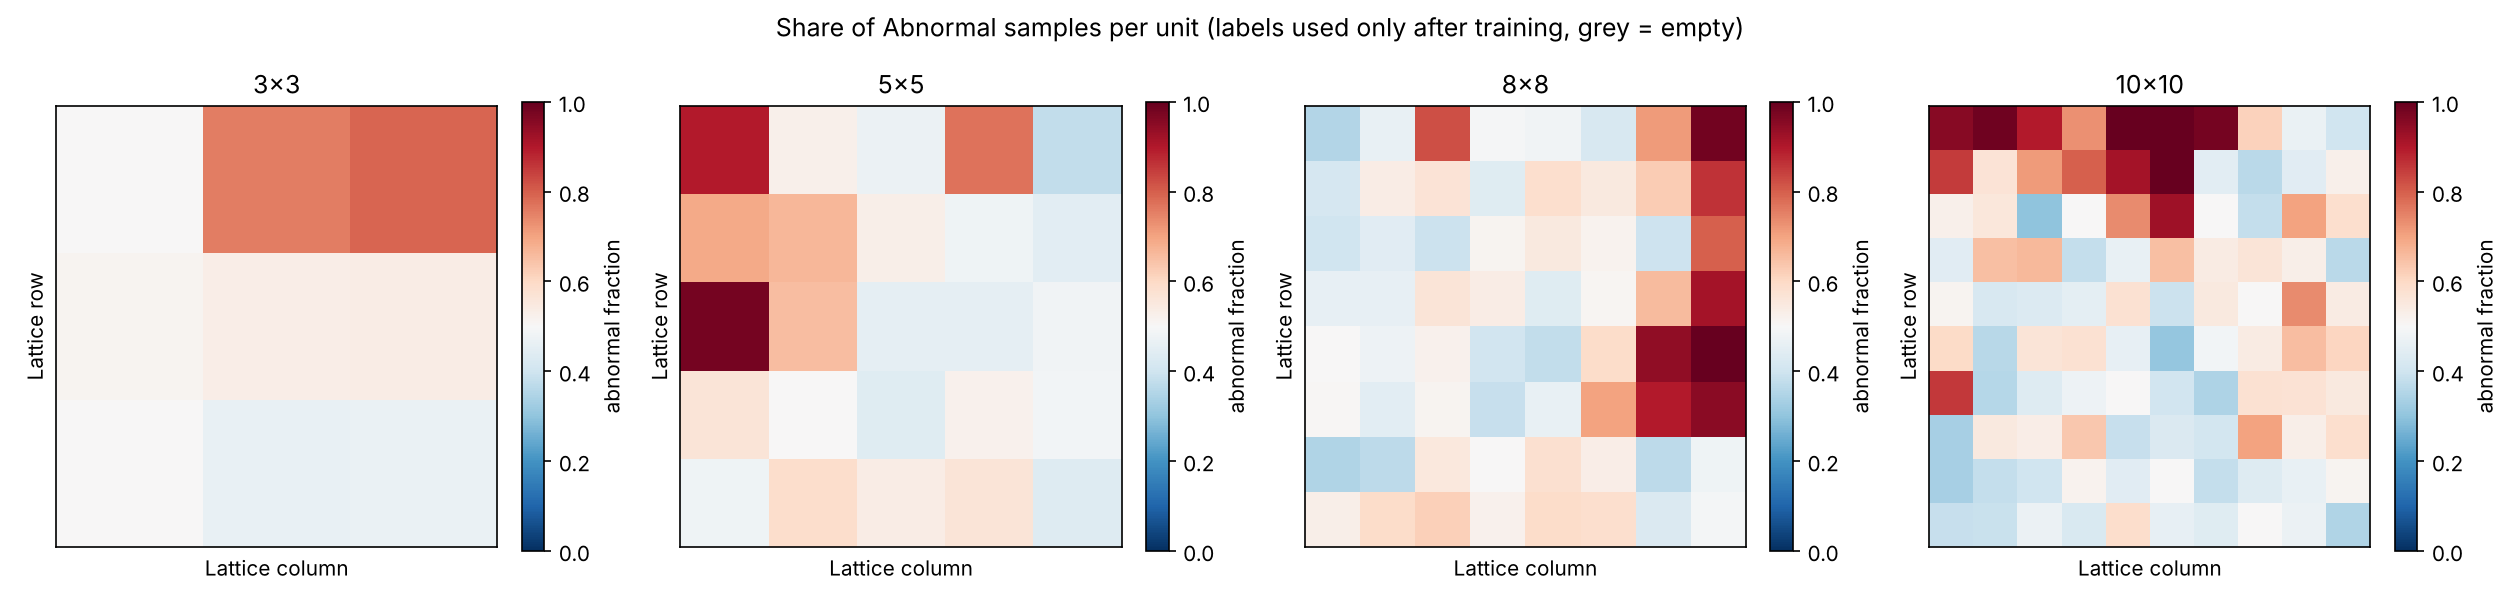

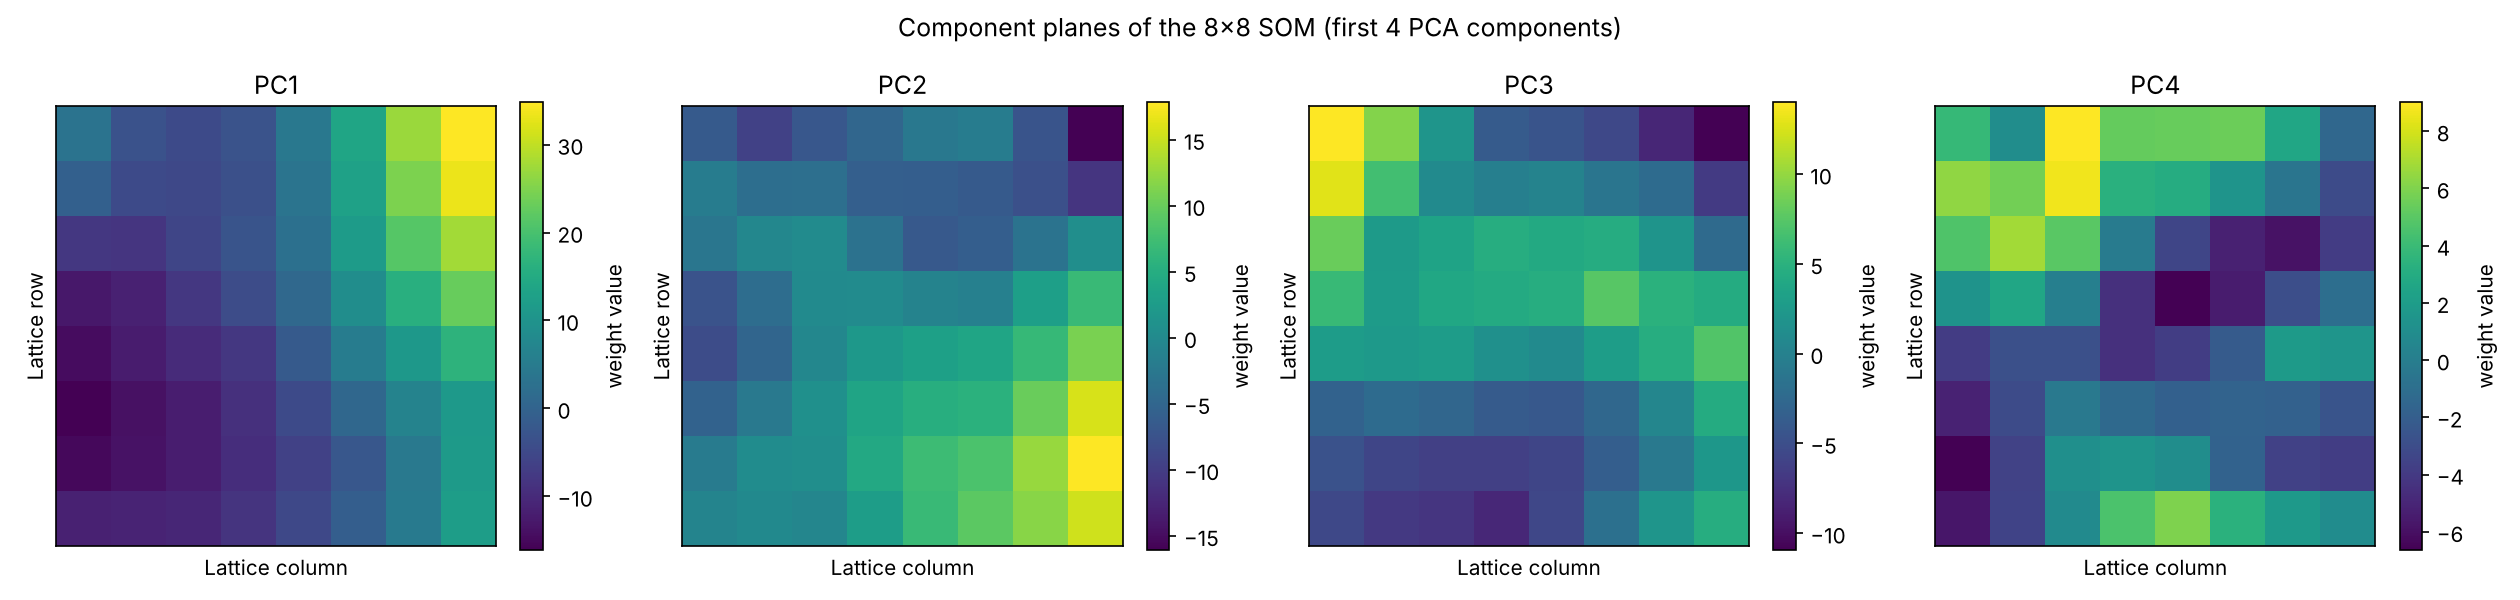

In [3]:
for f in ["som_u_matrix.png", "som_hit_maps.png", "som_normal_vs_abnormal.png", "som_component_planes_8x8.png"]:
    display(Image(filename=str(OUT / "figures" / f)))

## 3. Numerical example: BMU selection and one weight update
$w_j(t+1) = w_j(t) + \eta\, h_j\,(x - w_j(t))$, $h_j = \exp(-d_{grid}(j, bmu)^2 / 2\sigma^2)$, with $\eta = 0.5$, $\sigma = 1$.

In [4]:
ex = res["numerical_example"]
pd.DataFrame({"w_before": ex["W"], "distance_to_x": ex["distances"], "h": ex["neighbourhood_h"], "w_after": ex["W_updated"]},
             index=["neuron 1", "neuron 2", "neuron 3"])

,w_before,distance_to_x,h,w_after
neuron 1,"[0.1, 0.9]",0.9899,0.6065,"[0.3123, 0.6877]"
neuron 2,"[0.6, 0.4]",0.2828,1.0000,"[0.7, 0.3]"
neuron 3,"[0.9, 0.9]",0.7071,0.6065,"[0.8697, 0.6877]"
